In [56]:
!pip install -q streamlit
import tensorflow as tf
import numpy as np
import streamlit as st
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 96.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 91.7 MB/s eta 0:00:00


In [4]:
# Step 2: Load the dataset (replace 'creditcard.csv' with your file path if different)
df = pd.read_csv('/content/creditcard.csv')


In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [6]:
print("Dataset loaded. Shape:", df.shape)
print("Class distribution:\n", df['Class'].value_counts())  # 0: normal, 1: f

Dataset loaded. Shape: (35742, 31)
Class distribution:
 Class
0.0    35638
1.0      103
Name: count, dtype: int64


In [7]:
 #Check for missing values
# Check how many null/missing values are present in each column.
# A result of 0 means that the column has no missing values.
print("\n--- CHECKING NULL VALUES ---")
print(df.isnull().sum())


--- CHECKING NULL VALUES ---
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        1
V7        1
V8        1
V9        1
V10       1
V11       1
V12       1
V13       1
V14       1
V15       1
V16       1
V17       1
V18       1
V19       1
V20       1
V21       1
V22       1
V23       1
V24       1
V25       1
V26       1
V27       1
V28       1
Amount    1
Class     1
dtype: int64


In [8]:
# Step 4: Display information about the dataset
# df.info() shows important information about our dataset,
# including the number of rows, columns, column names,
# and the data type of each column.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35742 entries, 0 to 35741
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    35742 non-null  int64  
 1   V1      35742 non-null  float64
 2   V2      35742 non-null  float64
 3   V3      35742 non-null  float64
 4   V4      35742 non-null  float64
 5   V5      35742 non-null  float64
 6   V6      35741 non-null  float64
 7   V7      35741 non-null  float64
 8   V8      35741 non-null  float64
 9   V9      35741 non-null  float64
 10  V10     35741 non-null  float64
 11  V11     35741 non-null  float64
 12  V12     35741 non-null  float64
 13  V13     35741 non-null  float64
 14  V14     35741 non-null  float64
 15  V15     35741 non-null  float64
 16  V16     35741 non-null  float64
 17  V17     35741 non-null  float64
 18  V18     35741 non-null  float64
 19  V19     35741 non-null  float64
 20  V20     35741 non-null  float64
 21  V21     35741 non-null  float64
 22

In [9]:
# Check the number of observations in each class
# Class 0 = normal transaction
# Class 1 = fraudulent transaction
df['Class'].value_counts()

,count
Class,
0.0,35638
1.0,103


In [10]:
# Balance the dataset

# Select all fraudulent transactions
# Class 1 represents fraudulent transactions
fraud = df[df['Class'] == 1]

# Select all normal transactions
# Class 0 represents normal transactions
non_fraud = df[df['Class'] == 0]

# Check the shape of both classes
fraud.shape, non_fraud.shape

((103, 31), (35638, 31))

In [11]:
# Random selection of samples

# Randomly select 492 normal transactions
# There are 492 fraudulent transactions,
# so we select the same number of normal transactions
non_fraud_t = non_fraud.sample(n=492, random_state=0)

# Check the shape of the selected normal transactions
non_fraud_t.shape

(492, 31)

In [12]:
# Merge the two classes into one balanced dataset

# Combine the fraudulent transactions and selected normal transactions
dataset = pd.concat([fraud, non_fraud_t], ignore_index=True)

# Display the balanced dataset
print(dataset)



      Time        V1        V2        V3        V4        V5        V6  \
0      406 -2.312227  1.951992 -1.609851  3.997906 -0.522188 -1.426545   
1      472 -3.043541 -3.157307  1.088463  2.288644  1.359805 -1.064823   
2     4462 -2.303350  1.759247 -0.359745  2.330243 -0.821628 -0.075788   
3     6986 -4.397974  1.358367 -2.592844  2.679787 -1.128131 -1.706536   
4     7519  1.234235  3.019740 -4.304597  4.732795  3.624201 -1.357746   
..     ...       ...       ...       ...       ...       ...       ...   
590  34082  1.001387 -0.681780  1.602711  1.597707 -1.206234  1.426857   
591  33288 -0.306846  1.336865  1.388266  2.003322  1.010802 -0.088132   
592  33145 -2.142056 -5.549870 -1.129720  1.846988 -2.064570  1.203323   
593  31819  1.320471 -0.600363  0.292761 -0.751945 -0.943246 -0.528776   
594  35368  0.682951 -1.768940  1.387957 -0.905886 -1.741991  1.314714   

           V7        V8        V9  ...       V21       V22       V23  \
0   -2.537387  1.391657 -2.770089  ... 

In [13]:
# Observations in each class

# Count the number of transactions in each class
# Class 0 = normal transactions
# Class 1 = fraudulent transactions
dataset['Class'].value_counts()

,count
Class,
0.0,492
1.0,103


In [14]:
# Matrix of features

# Remove the 'Class' column from the dataset.
# The remaining 30 columns are the input features
# that will be given to the CNN model.
x = dataset.drop(labels=['Class'], axis=1)

# Dependent variable

# Store the 'Class' column as the target variable.
# Class 0 = normal transaction
# Class 1 = fraudulent transaction
y = dataset['Class']

# Check the shapes of the features and target
x.shape, y.shape

((595, 30), (595,))

In [15]:
# Splitting the dataset into train and test set

# Import the train_test_split function
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# 80% of the data will be used to train the CNN.
# 20% of the data will be used to test the CNN.
# random_state=0 makes the split reproducible.
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=0
)

# Check the shapes of the training and testing features
x_train.shape, x_test.shape

((476, 30), (119, 30))

In [16]:
# Feature scaling

# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create a StandardScaler object
# StandardScaler changes the features to a similar scale.
sc = StandardScaler()

# Fit the scaler on the training data and transform it
# fit_transform() calculates the mean and standard deviation
# from the training data and then scales the training data.
x_train = sc.fit_transform(x_train)

# Transform the test data using the same scaler
# We use transform() because the test data must use
# the scaling values calculated from the training data.
x_test = sc.transform(x_test)

# Display the scaled training data
x_train

array([[ 1.19711745e+00,  4.06932095e-03, -1.84866013e+00, ...,
        -5.75739083e-01,  5.34100286e-01,  4.97976086e+00],
       [ 2.56127882e-01,  5.25213742e-01, -3.14542337e-01, ...,
        -4.00209235e-01, -3.54714845e-02, -1.08993944e-01],
       [ 8.15399228e-01,  5.74989531e-01, -4.64787824e-01, ...,
        -2.70721000e-01, -1.63584213e-02, -2.72839406e-01],
       ...,
       [ 8.48709707e-02,  5.50023322e-01, -6.21953476e-01, ...,
        -2.05294645e-01,  3.34989683e-02, -1.32546729e-01],
       [ 1.17646588e+00,  5.35138655e-01, -2.61127983e-01, ...,
        -2.15087981e-01, -2.62491306e-02, -2.39924023e-01],
       [ 9.86236393e-01,  4.95331522e-01, -4.11457347e-01, ...,
        -1.76375658e-01, -2.44241659e-02, -3.00963773e-01]])

In [17]:
# Convert the training labels from Pandas Series to NumPy arrays
y_train = y_train.to_numpy()

# Convert the test labels from Pandas Series to NumPy arrays
y_test = y_test.to_numpy()

# Check the shapes of the training and test features
x_train.shape, x_test.shape

((476, 30), (119, 30))

In [18]:
# Reshape the dataset

# Reshape the training data into 3 dimensions dynamically using the actual number of samples
x_train = x_train.reshape(x_train.shape[0], 30, 1)

# Reshape the test data into 3 dimensions dynamically using the actual number of samples
x_test = x_test.reshape(x_test.shape[0], 30, 1)

# Check the new shapes
print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)

x_train shape: (476, 30, 1)
x_test shape: (119, 30, 1)


In [19]:
# Step 4: Building the model

# Defining the Sequential model
model = tf.keras.models.Sequential()


# First CNN layer
# Learns patterns from the transaction features.
model.add(tf.keras.layers.Conv1D(
    filters=32,
    kernel_size=2,
    padding='same',
    activation='relu',
    input_shape=(30, 1)
))


# Batch normalization
# Helps keep the values stable during training.
model.add(tf.keras.layers.BatchNormalization())


# MaxPool layer
# Reduces the size of the data while keeping important information.
model.add(tf.keras.layers.MaxPool1D(pool_size=2))


# Dropout layer
# Turns off 20% of neurons during training to reduce overfitting.
model.add(tf.keras.layers.Dropout(0.2))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
# Second CNN layer
# Learns more complex patterns from the first CNN layer.
model.add(tf.keras.layers.Conv1D(
    filters=64,
    kernel_size=2,
    padding='same',
    activation='relu'
))


# Batch normalization
# Helps stabilize the learning process.
model.add(tf.keras.layers.BatchNormalization())


# MaxPool layer
# Further reduces the size of the feature maps.
model.add(tf.keras.layers.MaxPool1D(pool_size=2))


# Dropout layer
# Turns off 30% of neurons during training.
# This helps reduce overfitting.
model.add(tf.keras.layers.Dropout(0.3))

In [21]:
# Flatten layer
# Converts the CNN output into a one-dimensional vector.
model.add(tf.keras.layers.Flatten())


# First Dense layer
# Contains 64 neurons and uses ReLU activation.
model.add(tf.keras.layers.Dense(
    units=64,
    activation='relu'
))


# Dropout layer
# Turns off 30% of neurons during training.
model.add(tf.keras.layers.Dropout(0.3))


# Output layer
# Contains 1 neuron because this is binary classification.
# Sigmoid produces a value between 0 and 1.
# 0 = normal transaction
# 1 = fraudulent transaction
model.add(tf.keras.layers.Dense(
    units=1,
    activation='sigmoid'
))


# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 32)         │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 15, 64)         │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 15, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        28,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,441 (130.63 KB)

 Trainable params: 33,249 (129.88 KB)

 Non-trainable params: 192 (768.00 B)

In [22]:
# Compile the model
# binary_crossentropy is used because this is
# a binary classification problem:
# 0 = normal transaction
# 1 = fraudulent transaction
#
# accuracy measures how many predictions are correct.
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [23]:
# Step 5: Training the model

# Train the CNN model
# x_train = training features
# y_train = training labels
# epochs=25 means the model will go through the training data 25 times.
# validation_data allows us to check the model's performance
# on the test data after each epoch.
history = model.fit(
    x_train,
    y_train,
    epochs=25,
    validation_data=(x_test, y_test)
)

Epoch 1/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.8634 - loss: 0.4303 - val_accuracy: 0.7563 - val_loss: 0.6021
Epoch 2/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9622 - loss: 0.1533 - val_accuracy: 0.9664 - val_loss: 0.4529
Epoch 3/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9748 - loss: 0.0921 - val_accuracy: 0.9748 - val_loss: 0.3793
Epoch 4/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9706 - loss: 0.0944 - val_accuracy: 0.9748 - val_loss: 0.3360
Epoch 5/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9685 - loss: 0.1070 - val_accuracy: 0.9748 - val_loss: 0.3232
Epoch 6/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9769 - loss: 0.0688 - val_accuracy: 0.9748 - val_loss: 0.2706
Epoch 7/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9748 - loss: 0.0608 - val_accuracy: 0.9748 - val_loss: 0.2369
Epoch 8/25
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9853 - loss: 0.0549 - val_accuracy: 0.9832 - va

In [24]:
# Model predictions

# Make prediction probabilities for the test data
y_pred_prob = model.predict(x_test)

# Convert prediction probabilities into class predictions
# If the probability is 0.5 or higher, predict Class 1 (fraud).
# If the probability is below 0.5, predict Class 0 (normal).
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

# Display one predicted value and its actual value
print(y_pred[12])
print(y_test[12])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
0
0.0


In [25]:
# Confusion matrix

from sklearn.metrics import confusion_matrix, accuracy_score

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
print("Confusion Matrix:")
print(cm)

# Calculate the accuracy
acc_cm = accuracy_score(y_test, y_pred)

# Display the accuracy
print("Accuracy:", acc_cm)

Confusion Matrix:
[[98  0]
 [ 2 19]]
Accuracy: 0.9831932773109243


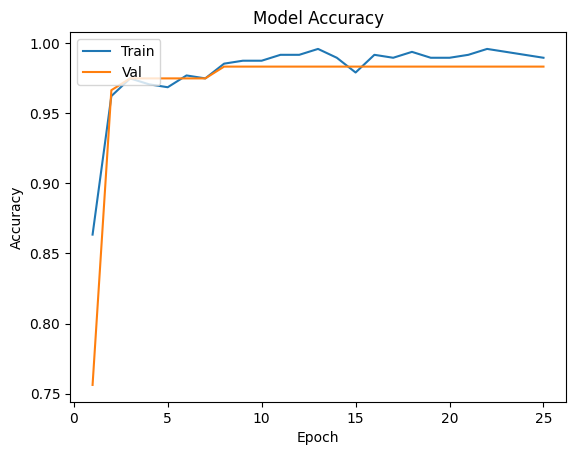

In [26]:
# Training vs Validation Accuracy

# Create the epoch numbers from 1 to 25
epoch_range = range(1, 26)

# Plot training accuracy
plt.plot(
    epoch_range,
    history.history['accuracy']
)

# Plot validation accuracy
plt.plot(
    epoch_range,
    history.history['val_accuracy']
)

# Add graph title
plt.title('Model Accuracy')

# Label the y-axis
plt.ylabel('Accuracy')

# Label the x-axis
plt.xlabel('Epoch')

# Add a legend
plt.legend(['Train', 'Val'], loc='upper left')

# Display the accuracy graph
plt.show()

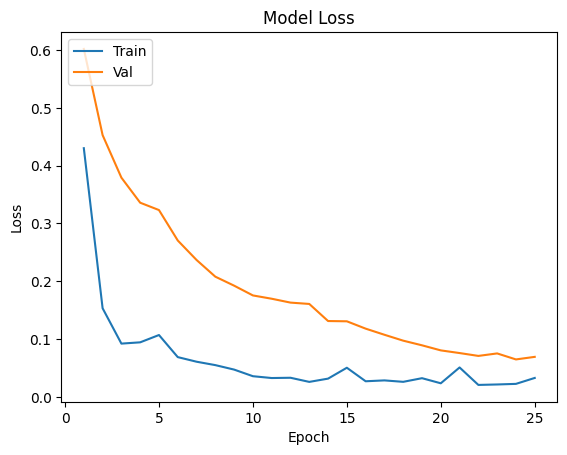

In [27]:
# Training vs Validation Loss

# Create the epoch numbers from 1 to 25
epoch_range = range(1, 26)

# Plot training loss
plt.plot(
    epoch_range,
    history.history['loss']
)

# Plot validation loss
plt.plot(
    epoch_range,
    history.history['val_loss']
)

# Add graph title
plt.title('Model Loss')

# Label the y-axis
plt.ylabel('Loss')

# Label the x-axis
plt.xlabel('Epoch')

# Add a legend
plt.legend(['Train', 'Val'], loc='upper left')

# Display the loss graph
plt.show()

In [28]:
y_pred_prob = model.predict(x_test)

y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


In [29]:
# Appendix E: CNN Classification Report and Performance Metrics

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [30]:
# Convert prediction probabilities to a 1D array
y_prob = y_pred_prob.ravel()

# Display classification report
print("CNN CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal Transaction", "Fraudulent Transaction"],
    digits=4
))

CNN CLASSIFICATION REPORT
                        precision    recall  f1-score   support

    Normal Transaction     0.9800    1.0000    0.9899        98
Fraudulent Transaction     1.0000    0.9048    0.9500        21

              accuracy                         0.9832       119
             macro avg     0.9900    0.9524    0.9699       119
          weighted avg     0.9835    0.9832    0.9829       119



In [31]:
# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("\nCNN PERFORMANCE METRICS")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")


CNN PERFORMANCE METRICS
Accuracy:  0.9832
Precision: 1.0000
Recall:    0.9048
F1-Score:  0.9500
ROC-AUC:   0.9849


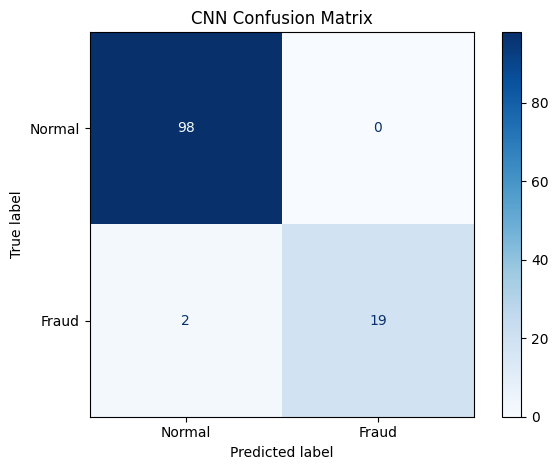

In [32]:
# Display a labelled confusion matrix
cm = confusion_matrix(y_test, y_pred)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)

display_cm.plot(cmap="Blues", values_format="d")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

In [33]:
# Appendix F: Comparison of Three Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd
import numpy as np

In [34]:
# Convert the CNN data from 3D back to 2D
# Traditional models require a 2D feature matrix.
X_train_2d = x_train.reshape(x_train.shape[0], -1)
X_test_2d = x_test.reshape(x_test.shape[0], -1)

# Train Logistic Regression
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)
logistic_model.fit(X_train_2d, y_train)


LogisticRegression(max_iter=2000, random_state=42)

In [35]:
# Train Random Forest
forest_model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    class_weight="balanced"
)
forest_model.fit(X_train_2d, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=150,
                       random_state=42)

In [36]:
# Get predictions and probabilities
logistic_pred = logistic_model.predict(X_test_2d)
logistic_prob = logistic_model.predict_proba(X_test_2d)[:, 1]

forest_pred = forest_model.predict(X_test_2d)
forest_prob = forest_model.predict_proba(X_test_2d)[:, 1]

In [37]:
# Function to calculate the metrics for each model
def evaluate_model(name, actual, predicted, probability):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1-Score": f1_score(actual, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(actual, probability)
    }

In [38]:
# Build the comparison table
comparison_df = pd.DataFrame([
    evaluate_model(
        "Logistic Regression", y_test, logistic_pred, logistic_prob
    ),
    evaluate_model(
        "Random Forest", y_test, forest_pred, forest_prob
    ),
    evaluate_model(
        "CNN", y_test, y_pred, y_prob
    )
])

# Display the results
print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9832,1.0,0.9048,0.95,0.9602
1,Random Forest,0.9832,1.0,0.9048,0.95,0.9925
2,CNN,0.9832,1.0,0.9048,0.95,0.9849


In [39]:
# APPENDIX G: DEPLOYMENT EVIDENCE

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

os.makedirs("appendix_evidence", exist_ok=True)

# Save the existing trained CNN
model.save("credit_card_fraud_cnn.keras")
print("CNN model saved successfully.")

CNN model saved successfully.


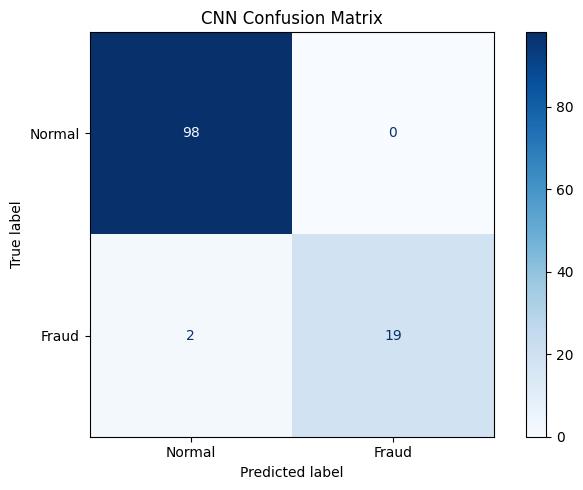

Confusion matrix saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
# Save confusion matrix evidence
if "y_test" in globals() and "y_pred" in globals():
    y_true = np.asarray(y_test).ravel().astype(int)
    y_hat = np.asarray(y_pred).ravel().astype(int)

    cm = confusion_matrix(y_true, y_hat)

    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Fraud"]
    ).plot(ax=ax, cmap="Blues", values_format="d")

    ax.set_title("CNN Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        "appendix_e_confusion_matrix.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

    print("Confusion matrix saved successfully.")
else:
    print("Run your prediction cells first to define y_test and y_pred.")

# Download the saved CNN model
from google.colab import files
files.download("credit_card_fraud_cnn.keras")

CREDIT CARD FRAUD DETECTION - TEST RESULTS
Test samples: 119
Correct predictions: 117
Incorrect predictions: 2
Accuracy:  0.9832 (98.32%)
Precision: 1.0000 (100.00%)
Recall:    0.9048 (90.48%)
F1-score:  0.9500 (95.00%)
ROC-AUC:   0.9849

CLASSIFICATION REPORT
                        precision    recall  f1-score   support

    Normal Transaction     0.9800    1.0000    0.9899        98
Fraudulent Transaction     1.0000    0.9048    0.9500        21

              accuracy                         0.9832       119
             macro avg     0.9900    0.9524    0.9699       119
          weighted avg     0.9835    0.9832    0.9829       119



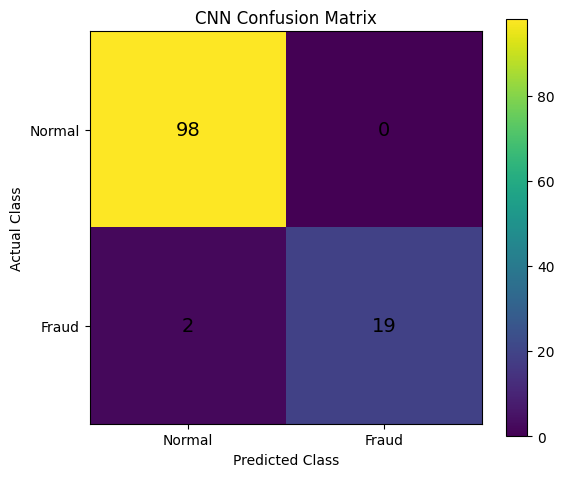

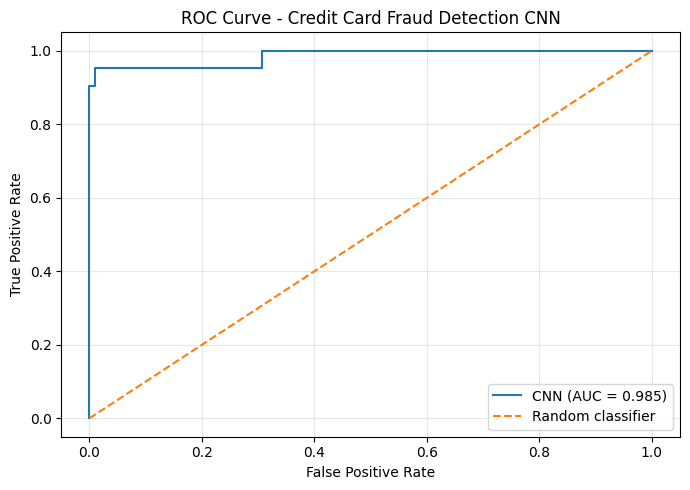

In [41]:

# APPENDIX E: COMPLETE MODEL PERFORMANCE EVALUATION

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

# Ensure predictions are in the correct format
actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred).ravel()
probabilities = np.asarray(y_pred_prob).ravel()

# Calculate the confusion matrix and performance metrics
cm = confusion_matrix(actual, predicted)

accuracy = accuracy_score(actual, predicted)
precision = precision_score(actual, predicted, zero_division=0)
recall = recall_score(actual, predicted, zero_division=0)
f1 = f1_score(actual, predicted, zero_division=0)
auc = roc_auc_score(actual, probabilities)

print("CREDIT CARD FRAUD DETECTION - TEST RESULTS")
print("=" * 48)
print(f"Test samples: {len(actual)}")
print(f"Correct predictions: {(actual == predicted).sum()}")
print(f"Incorrect predictions: {(actual != predicted).sum()}")
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score:  {f1:.4f} ({f1 * 100:.2f}%)")
print(f"ROC-AUC:   {auc:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    actual,
    predicted,
    labels=[0, 1],
    target_names=["Normal Transaction", "Fraudulent Transaction"],
    digits=4,
    zero_division=0
))

# Save a clear confusion-matrix visualisation
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("CNN Confusion Matrix")
plt.colorbar()
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.yticks([0, 1], ["Normal", "Fraud"])
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center", fontsize=14)

plt.tight_layout()
plt.savefig("appendix_e_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Generate and save the ROC curve
fpr, tpr, thresholds = roc_curve(actual, probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"CNN (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--",
         label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Credit Card Fraud Detection CNN")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("appendix_e_roc_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [42]:
# APPENDIX F: MODEL COMPARISON
# CNN vs Logistic Regression vs Random Forest
# Reuses the existing CNN; does NOT retrain it.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [43]:
# 1. Check that the required variables exist
required = ["x_train", "x_test", "y_train", "y_test", "model"]
missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "Run the earlier data preparation and CNN training cells first."
    )

In [44]:
# 2. Prepare labels and features for traditional ML models
y_train_f = np.asarray(y_train).ravel().astype(int)
y_test_f = np.asarray(y_test).ravel().astype(int)

X_train_f = np.asarray(x_train)
X_test_f = np.asarray(x_test)

In [45]:
# Traditional models require 2D input.
# This also supports your CNN's (samples, features, 1) format.
X_train_f = X_train_f.reshape(X_train_f.shape[0], -1)
X_test_f = X_test_f.reshape(X_test_f.shape[0], -1)

In [46]:
# 3. Reuse the trained CNN to obtain its test predictions
cnn_output = np.asarray(model.predict(x_test, verbose=0))

if cnn_output.ndim == 2 and cnn_output.shape[1] == 2:
    cnn_prob = cnn_output[:, 1]
    cnn_pred = np.argmax(cnn_output, axis=1)
else:
    cnn_prob = cnn_output.reshape(-1)
    cnn_pred = (cnn_prob >= 0.5).astype(int)

In [47]:
# 4. Train two traditional models on the existing training data
print("Training Logistic Regression...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_f, y_train_f)

print("Training Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_f, y_train_f)

Training Logistic Regression...
Training Random Forest...


RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

In [48]:
# 5. Get predictions and fraud probabilities
lr_pred = lr_model.predict(X_test_f)
lr_prob = lr_model.predict_proba(X_test_f)[:, 1]

rf_pred = rf_model.predict(X_test_f)
rf_prob = rf_model.predict_proba(X_test_f)[:, 1]



In [49]:
# 6. Calculate comparable metrics on the same test set
models_results = [
    ("CNN", cnn_pred, cnn_prob),
    ("Logistic Regression", lr_pred, lr_prob),
    ("Random Forest", rf_pred, rf_prob)
]

results = []

for name, predictions, probabilities in models_results:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_f, predictions),
        "Precision": precision_score(
            y_test_f, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_f, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_f, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_f, probabilities)
    })

comparison_df = pd.DataFrame(results)

print("\nAPPENDIX F: MODEL COMPARISON RESULTS")
print("=" * 65)
print(f"Test samples: {len(y_test_f)}")
display(comparison_df.round(4))




APPENDIX F: MODEL COMPARISON RESULTS
Test samples: 119


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,CNN,0.9832,1.0,0.9048,0.95,0.9849
1,Logistic Regression,0.9832,1.0,0.9048,0.95,0.9602
2,Random Forest,0.9832,1.0,0.9048,0.95,0.9742


Saved: appendix_f_model_comparison.csv


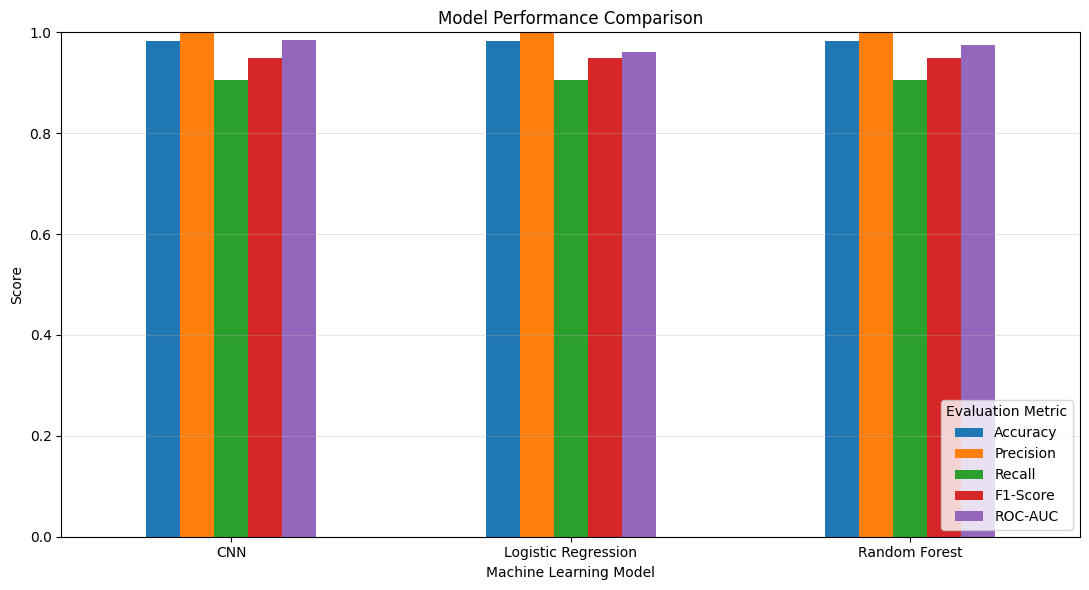

Saved: appendix_f_model_comparison.png


In [50]:
# 7. Save the comparison table
comparison_df.to_csv(
    "appendix_f_model_comparison.csv", index=False
)
print("Saved: appendix_f_model_comparison.csv")

# 8. Create and save the comparison graph
metric_columns = [
    "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"
]

plot_df = comparison_df.set_index("Model")[metric_columns]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Machine Learning Model")
ax.legend(title="Evaluation Metric", loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "appendix_f_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: appendix_f_model_comparison.png")



In [51]:
# 9. Display the classification report for each model
for name, predictions, probabilities in models_results:
    print(f"\nCLASSIFICATION REPORT: {name}")
    print(
        classification_report(
            y_test_f,
            predictions,
            labels=[0, 1],
            target_names=[
                "Normal Transaction",
                "Fraudulent Transaction"
            ],
            digits=4,
            zero_division=0
        )
    )


CLASSIFICATION REPORT: CNN
                        precision    recall  f1-score   support

    Normal Transaction     0.9800    1.0000    0.9899        98
Fraudulent Transaction     1.0000    0.9048    0.9500        21

              accuracy                         0.9832       119
             macro avg     0.9900    0.9524    0.9699       119
          weighted avg     0.9835    0.9832    0.9829       119


CLASSIFICATION REPORT: Logistic Regression
                        precision    recall  f1-score   support

    Normal Transaction     0.9800    1.0000    0.9899        98
Fraudulent Transaction     1.0000    0.9048    0.9500        21

              accuracy                         0.9832       119
             macro avg     0.9900    0.9524    0.9699       119
          weighted avg     0.9835    0.9832    0.9829       119


CLASSIFICATION REPORT: Random Forest
                        precision    recall  f1-score   support

    Normal Transaction     0.9800    1.0000    0.98

In [52]:
# Appendix G: Save the existing trained CNN model
# This does not retrain the model.

import os

model_path = "/content/credit_card_fraud_cnn.keras"

model.save(model_path)

print("Model saved successfully.")
print("File:", model_path)
print("File exists:", os.path.exists(model_path))
print("File size (MB):", round(os.path.getsize(model_path) / (1024 * 1024), 2))

Model saved successfully.
File: /content/credit_card_fraud_cnn.keras
File exists: True
File size (MB): 0.43


In [53]:
# Appendix H: Check existing model and test data

print("CNN model available:", "model" in globals())
print("Test data available:", "x_test" in globals())
print("Test labels available:", "y_test" in globals())
print("Feature dataframe available:", "df" in globals())

if "x_test" in globals():
    print("Test data shape:", x_test.shape)

if "df" in globals():
    print("Dataset shape:", df.shape)
    print("Feature columns:", list(df.columns)[:10])

CNN model available: True
Test data available: True
Test labels available: True
Feature dataframe available: True
Test data shape: (119, 30, 1)
Dataset shape: (35742, 31)
Feature columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9']


Baseline CNN F1-score: 0.9500
Number of test transactions: 119
Number of input features: 30

Top 10 features by permutation importance:


,Feature,Mean F1 Score Drop,Std F1 Score Drop
0,V12,0.0691,0.0157
1,V4,0.0528,0.0294
2,V10,0.0334,0.0394
3,V2,0.0315,0.0410
4,V13,0.0232,0.0000
5,V7,0.0178,0.0175
6,V22,0.0139,0.0114
7,V16,0.0132,0.0109
8,V18,0.0125,0.0239
9,V25,0.0093,0.0114


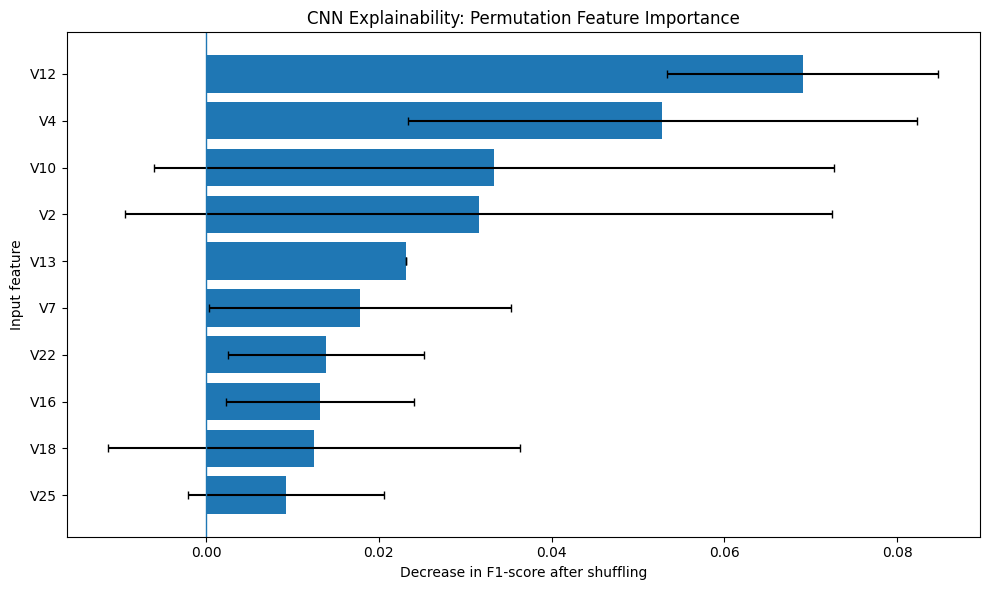


Saved files:
- appendix_h_feature_importance.csv
- appendix_h_permutation_importance.png


In [54]:

# APPENDIX H: CNN FEATURE EXPLAINABILITY
# Uses the existing trained CNN. Does not retrain the model.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score

# 1. Check required variables
required = ["model", "x_test", "y_test", "df"]
missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. Run the earlier notebook cells first."
    )

# 2. Prepare test data
X_eval = np.asarray(x_test).copy()
y_eval = np.asarray(y_test).reshape(-1).astype(int)

if X_eval.ndim != 3:
    raise ValueError(
        f"Expected test data with 3 dimensions; got {X_eval.shape}"
    )

n_features = X_eval.shape[1]

# Exclude the target column from the feature names
target_col = "Class" if "Class" in df.columns else None
feature_names = [
    col for col in df.columns if col != target_col
]

# Fall back to generic names if column counts do not match
if len(feature_names) != n_features:
    feature_names = [
        f"Feature_{i + 1}" for i in range(n_features)
    ]

# 3. Get predictions from the existing model
def get_predictions(data):
    probabilities = np.asarray(
        model.predict(data, verbose=0)
    )

    if probabilities.ndim == 2 and probabilities.shape[1] == 2:
        fraud_prob = probabilities[:, 1]
        predicted = np.argmax(probabilities, axis=1)
    else:
        fraud_prob = probabilities.reshape(-1)
        predicted = (fraud_prob >= 0.5).astype(int)

    return predicted, fraud_prob

baseline_pred, _ = get_predictions(X_eval)
baseline_f1 = f1_score(
    y_eval, baseline_pred, zero_division=0
)

print(f"Baseline CNN F1-score: {baseline_f1:.4f}")
print(f"Number of test transactions: {len(y_eval)}")
print(f"Number of input features: {n_features}")

# 4. Shuffle each feature and measure the F1-score drop
rng = np.random.default_rng(42)
n_repeats = 5
importance_results = []

for feature_idx in range(n_features):
    score_drops = []

    for _ in range(n_repeats):
        shuffled = X_eval.copy()
        shuffled_indices = rng.permutation(len(shuffled))

        # Shuffle one feature across test transactions
        shuffled[:, feature_idx, :] = (
            X_eval[shuffled_indices, feature_idx, :]
        )

        shuffled_pred, _ = get_predictions(shuffled)
        shuffled_f1 = f1_score(
            y_eval, shuffled_pred, zero_division=0
        )

        score_drops.append(baseline_f1 - shuffled_f1)

    importance_results.append({
        "Feature": feature_names[feature_idx],
        "Mean F1 Score Drop": np.mean(score_drops),
        "Std F1 Score Drop": np.std(score_drops)
    })

importance_df = pd.DataFrame(importance_results)
importance_df = importance_df.sort_values(
    "Mean F1 Score Drop", ascending=False
).reset_index(drop=True)

# 5. Save the explainability table
importance_df.to_csv(
    "appendix_h_feature_importance.csv", index=False
)

print("\nTop 10 features by permutation importance:")
display(importance_df.head(10).round(4))

# 6. Plot the 10 most important features
top_features = importance_df.head(10).sort_values(
    "Mean F1 Score Drop", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Mean F1 Score Drop"],
    xerr=top_features["Std F1 Score Drop"],
    capsize=3
)
plt.axvline(0, linewidth=1)
plt.xlabel("Decrease in F1-score after shuffling")
plt.ylabel("Input feature")
plt.title("CNN Explainability: Permutation Feature Importance")
plt.tight_layout()

plt.savefig(
    "appendix_h_permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSaved files:")
print("- appendix_h_feature_importance.csv")
print("- appendix_h_permutation_importance.png")

